# **Langkah 3.2 Citra Biner Awal**
**Kode 3.1 Mask daun awal dan bercak awal**

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/SIMUTEH/simuteh-2330511078"
SRC_DIR = os.path.join(BASE_DIR, "src")

sys.path.insert(0, SRC_DIR)

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import iou, mask_daun_awal, bercak_awal

import json

from praproses import PARAM_BAWAAN

PARAM = PARAM_BAWAAN.copy()
# Fungsi untuk memuat citra dan mask

def muat(nama):
    img = baca(
        os.path.join(BASE_DIR, "data", "sintetis", "citra", nama))

    md = cv2.imread(
        os.path.join(BASE_DIR, "data", "sintetis", "mask_daun", nama), 0)

    mb = cv2.imread(
        os.path.join(BASE_DIR, "data", "sintetis", "mask_bercak", nama), 0)

    return img, md, mb

         citra  IoU daun awal  komponen bercak awal  komponen acuan  \
0  teh_041.png          0.997                   198               8   
1  teh_021.png          0.993                   200               1   
2  teh_011.png          0.997                   141               0   

  IoU bercak awal  
0           0.451  
1           0.049  
2               -  


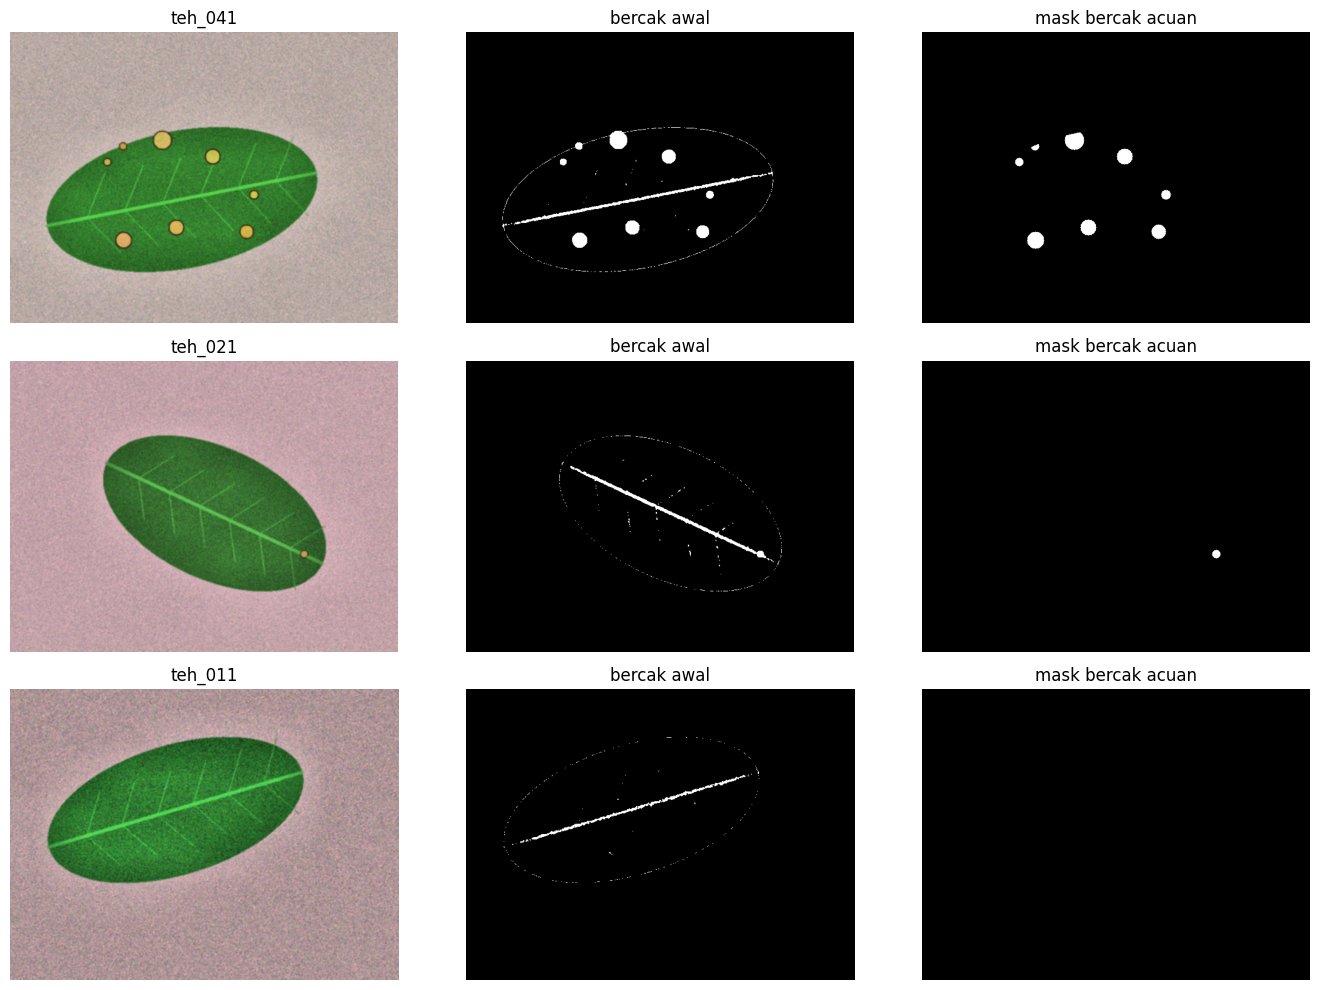

In [29]:
# Kode 3.1 Mask daun awal dan bercak awal

def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )[0] - 1

baris, panel, judul = [], [], []

for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat

    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)

    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-" ])

    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(
    baris,
    columns=[
        "citra",
        "IoU daun awal",
        "komponen bercak awal",
        "komponen acuan",
        "IoU bercak awal" ]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

#**Langkah 3.3 Enam Operasi**

**Kode 3.2 Erosi, dilasi opening dan closing**

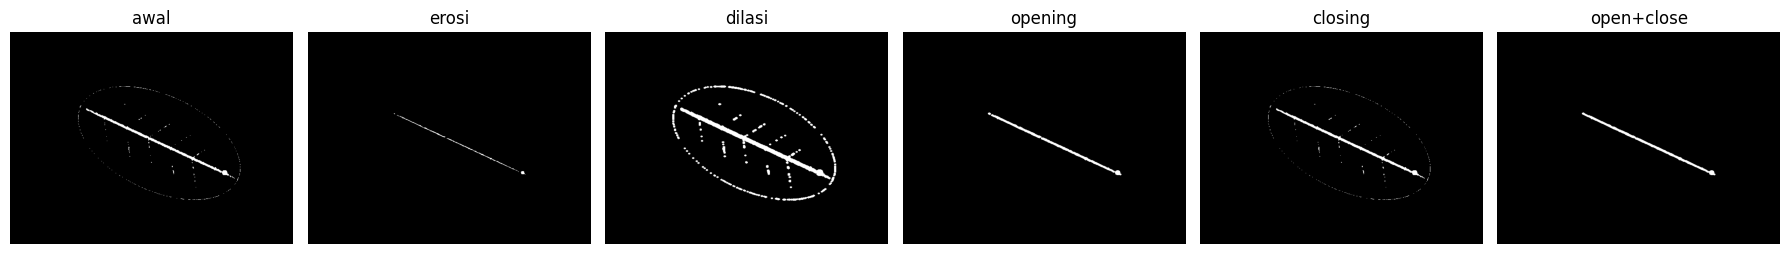

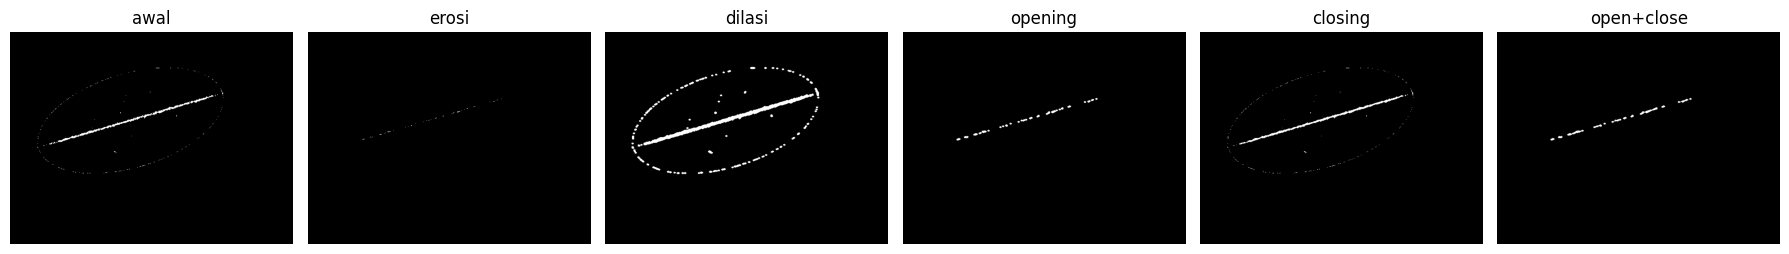

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       200    2398  0.049
1   teh_021.png       erosi         8     535  0.079
2   teh_021.png      dilasi        84    7508   0.02
3   teh_021.png     opening         1    1788  0.063
4   teh_021.png     closing       187    2472  0.048
5   teh_021.png  open+close         1    1815  0.063
6   teh_011.png        awal       141    1725      -
7   teh_011.png       erosi        35      74      -
8   teh_011.png      dilasi        76    5772      -
9   teh_011.png     opening        21     701      -
10  teh_011.png     closing       135    1872      -
11  teh_011.png  open+close        13     761      -


In [30]:
# Kode 3.2 Erosi, dilasi, opening, dan closing

SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(
    bentuk, (k, k))

def operasi(b, se):
    return {
        "awal": b,
        "erosi": cv2.erode(b, se),
        "dilasi": cv2.dilate(b, se),
        "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
        "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
        "open+close": cv2.morphologyEx(
            cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            cv2.MORPH_CLOSE,
            se )}

baris = []

for nama in ["teh_021.png", "teh_011.png"]:

    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(
        pra_,
        mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))

    for nm, m in hasil.items():
        baris.append([
            nama,
            nm,
            jumlah_komponen(m),
            int((m > 0).sum()),
            round(iou(m, mb), 3) if mb.any() else "-"
        ])

    tampil(
        list(hasil.values()),
        list(hasil.keys()),
        ukuran=(18, 3))
    plt.show()

print(pd.DataFrame(
    baris,
    columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

#**Langkah 3.4 Eksperimen ambang dan SE**

**Kode 3.3 Eksperimen K, bentuk dan ukuran SE**


In [31]:
# Memuat label dataset

label = pd.read_csv(
    os.path.join(BASE_DIR, "data", "sintetis", "label.csv")
)

# Memeriksa isi dataset
print(label.head())
print("Jumlah data:", len(label))

     nama_file  kelas  kondisi_cahaya  persen_bercak
0  teh_001.png  sehat          normal            0.0
1  teh_002.png  sehat           gelap            0.0
2  teh_003.png  sehat          terang            0.0
3  teh_004.png  sehat  kontras_rendah            0.0
4  teh_005.png  sehat        bayangan            0.0
Jumlah data: 60


In [32]:
# Kode 3.3 Eksperimen k, bentuk, dan ukuran SE

bentuk = {
    "persegi": cv2.MORPH_RECT,
    "elips": cv2.MORPH_ELLIPSE,
    "silang": cv2.MORPH_CROSS}

baris = []

for _, d in label.iterrows():

    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)

    for k in [3, 4, 6]:

        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:

                se = SE(uk, kb)
                m = cv2.morphologyEx(
                    cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
                    cv2.MORPH_CLOSE,
                    se)

                baris.append([
                    d.kelas, k, nb, uk,
                    abs(jumlah_komponen(m) - n_acuan),
                    iou(m, mb) if mb.any() else np.nan])

eks = pd.DataFrame(
    baris,
    columns=[
        "kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU" ])

print(
    eks.pivot_table(
        index=["k", "bentuk", "ukuran"],
        columns="kelas",
        values=["galat_jumlah", "IoU"]
    ).round(2))

# Simpan hasil eksperimen ke folder hasil proyek

folder_hasil = os.path.join(BASE_DIR, "hasil")
os.makedirs(folder_hasil, exist_ok=True)

file_hasil = os.path.join(
    folder_hasil,
    "p6_eksperimen_se.csv")

eks.to_csv(file_hasil, index=False)
print("Hasil berhasil disimpan:", file_hasil)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.60   0.20        16.40  14.80  22.40
          5       0.63   0.26         2.80   4.05   3.55
          7       0.71   0.44         1.15   3.00   2.00
  persegi 3       0.61   0.21         5.00   7.95   7.40
          5       0.66   0.34         3.25   3.40   3.10
          7       0.70   0.56         0.30   0.45   0.00
  silang  3       0.60   0.20        16.40  14.80  22.40
          5       0.63   0.26         5.45   6.65   5.90
          7       0.71   0.42         3.45   4.35   3.95
4 elips   3       0.65   0.32        12.15   9.85   8.35
          5       0.67   0.39         2.30   2.60   2.95
          7       0.69   0.53         0.50   1.35   0.30
  persegi 3       0.65   0.34         5.50   5.00   4.85
          5       0.68   0.49         1.35   2.15   1.30
          7       0.66   0.53  

#**Langkah 3.5 Gradien Sebagai tepi Daun**

**Kode 3.4 Gradien morfologi dibandingkan dengan Canny**

In [33]:
import utils_tepi

print([nama for nama in dir(utils_tepi) if "canny" in nama.lower()])

[]


In [34]:
# Kode 3.4 Gradien morfologi dibandingkan dengan Canny

from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    # Gradien morfologi: dilasi dikurangi erosi
    grad = cv2.morphologyEx(
        m_daun,
        cv2.MORPH_GRADIENT,
        SE(3) )

    # Deteksi tepi menggunakan Canny
    gray = cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (0, 0), 1)
    canny = cv2.Canny(blur, 100, 200)

    # Tepi acuan daun
    ad = tepi_acuan(md)

    # Menghitung F1 masing-masing metode
    baris.append([
        d.kondisi_cahaya,
        skor_tepi(grad, ad)[2],
        skor_tepi(canny, ad)[2]
    ])

# Membuat tabel hasil
hasil_gradien = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "F1 gradien morfologi",
        "F1 Canny"])

# Menampilkan rata-rata F1 berdasarkan kondisi cahaya
print(
    hasil_gradien.groupby("kondisi")
    .mean()
    .round(3)
)

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.814     0.862
gelap                          0.982     0.797
kontras_rendah                 0.289     0.927
normal                         0.984     0.774
terang                         0.908     0.901


##**Langkah 3.5 mengejakan sendiri**

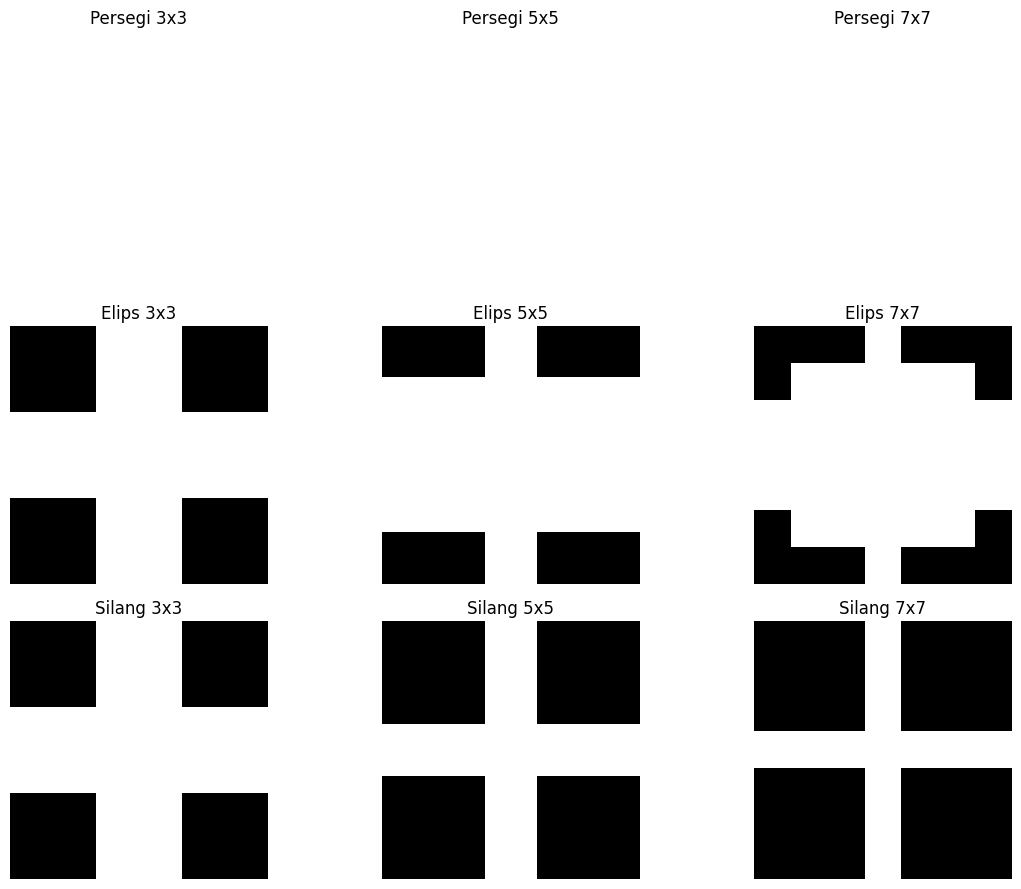

In [35]:
# Langkah 3.5 Visualisasi bentuk dan ukuran SE

bentuk = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

ukuran = [3, 5, 7]
panel = []
judul = []

for nama_bentuk, jenis in bentuk.items():
    for k in ukuran:
        se = cv2.getStructuringElement(
            jenis, (k, k)
        )

        panel.append(se * 255)
        judul.append(f"{nama_bentuk} {k}x{k}")

# Menampilkan 9 variasi SE dalam 3 baris
tampil(
    panel,
    judul,
    baris=3,
    ukuran=(12, 9)
)

plt.show()

#**Langkah 4.2 Label dan ukur**

**Kode 4.1 Komponen terhubung dan pengukuran setiap bercak**

konektivitas 4: 13 komponen
konektivitas 8: 13 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      709    135.71         95.8       0.97         1.04  250  177
1       2      122     23.35         38.1       1.05         1.00  185  187
2       3      430     82.30         73.9       0.99         1.00  334  204
3       4      100     19.14         34.7       1.04         1.00  159  213
4       5       41      7.85         24.5       0.86         2.17  455  241
5       6      923    176.67        473.3       0.05        31.61  345  263
6       7      136     26.03         41.0       1.02         1.00  401  268
7       8      606    115.99        292.8       0.09        21.94  172  297
8       9        1      0.19          0.0       0.00         0.00  239  284
9      10       31      5.93         20.5       0.93         1.89  100  311
10     11      437     83.64         75.1       0.97         1.00  273  322
11     12      363     69.48    

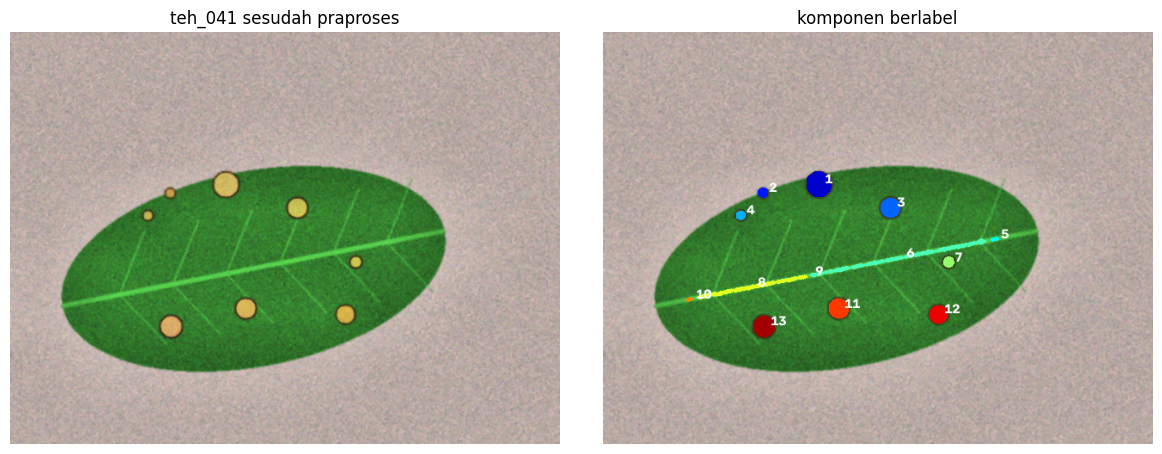

In [36]:
# Kode 4.1 Komponen terhubung dan pengukuran setiap bercak

MM_PER_PX = 0.4375  # 1 piksel = 0,4375 mm

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (m > 0).astype(np.uint8),
        connectivity=konek)

    baris = []

    for i in range(1, n):
        kontur, _ = cv2.findContours(
            (lbl == i).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE)

        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)

        kebulatan = (
            0.0 if keliling == 0
            else 4 * np.pi * A / keliling**2)

        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)

        baris.append([
            i, A,
            round(A * MM_PER_PX**2, 2),
            round(keliling, 1),
            round(kebulatan, 2),
            round(rasio, 2),
            int(cen[i][0]),
            int(cen[i][1]) ])

    kolom = [
        "label",
        "luas_px",
        "luas_mm2",
        "keliling_px",
        "kebulatan",
        "rasio_aspek",
        "cx",
        "cy" ]

    return pd.DataFrame(baris, columns=kolom), lbl

# Memuat citra
img, md, mb = muat("teh_041.png")

# Praproses dan membuat mask daun
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)

# Membersihkan mask bercak menggunakan opening dan closing
bersih = cv2.morphologyEx(
    cv2.morphologyEx(
        bercak_awal(pra_, m_daun),
        cv2.MORPH_OPEN,
        SE(5)
    ),
    cv2.MORPH_CLOSE,
    SE(5) )

# Membandingkan jumlah komponen konektivitas 4 dan 8
for konek in [4, 8]:
    print(
        f"konektivitas {konek}: "
        f"{jumlah_komponen(bersih, konek)} komponen" )

# Mengukur komponen dengan konektivitas 8
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

# Memberi warna pada setiap komponen
warna = cv2.applyColorMap(
    (lbl * (255 // max(lbl.max(), 1))).astype(np.uint8),
    cv2.COLORMAP_JET)

warna[lbl == 0] = pra_[lbl == 0]

# Menambahkan nomor label pada gambar
for _, r in tabel_kom.iterrows():
    cv2.putText(
        warna,
        str(int(r.label)),
        (int(r.cx) + 8, int(r.cy)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5, (255, 255, 255), 2)

# Menampilkan hasil
tampil(
    [pra_, warna],
    ["teh_041 sesudah praproses", "komponen berlabel"],
    ukuran=(12, 4.5) )

plt.show()

#**Langkah 4.3 Saring Bercak Palsu

**Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk**

In [37]:
# Langkah 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk

def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)

    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)]

    return (
        np.isin(lbl, lolos.label.values) * 255
    ).astype(np.uint8), lolos

# Empat aturan penyaringan
aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8) }

# Pengujian pada seluruh 60 citra
baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE(5)
        ),
        cv2.MORPH_CLOSE,
        SE(5) )

    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)

        baris.append([
            d.kelas,
            nm,
            jumlah_komponen(f),
            jumlah_komponen(mb) ])

# Menghitung galat jumlah komponen
uji = pd.DataFrame(
    baris,
    columns=["kelas", "aturan", "jumlah", "acuan"])

uji["galat"] = (uji.jumlah - uji.acuan).abs()


# Menampilkan tabel galat setiap kelas
print(
    uji.pivot_table(
        index="aturan",
        columns="kelas",
        values="galat"
    ).round(2))

# Menghitung jumlah citra daun sehat yang masih memiliki bercak palsu
print("Daun sehat yang masih memiliki bercak palsu:")
print(
    uji[uji.kelas == "sehat"]
    .assign(palsu=lambda t: t.jumlah > 0)
    .groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.10    1.35   1.25
luas + kebulatan + rasio   0.85    0.75   0.60
luas >= 20                 1.55    2.05   2.25
tanpa saring               2.30    2.60   2.95
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             8
luas + kebulatan + rasio     6
luas >= 20                   9
tanpa saring                10
Name: palsu, dtype: int64


#**Langkah 4.4 Kerjakan Sendiri: Dasar ambang Penyaringan**

Yang dikerjakan utama:

1.   Mengabil setiap komponen bercak dari hasil pembersihan
2.   Memberikan label benar atau palsu berdasarkan perbandingan dengan mask_bercak acuan
3.   Membuat diaram sebar (scatter plot) antara kebuatan dan rasio aspek

Aturan pelabelannya:
- Benar: lebih dari 50% piksel komponen berada di dalam mask_bercak acuan.
- Palsu: 50% atau kurang piksel komponen berada di dalam mask_bercak acuan.




In [38]:

# Kode 4.3 Mengerjakan sendirii

baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    # Mask bercak hasil pembersihan
    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE(5)
        ),
        cv2.MORPH_CLOSE,
        SE(5))

    # Melabeli dan mengukur setiap komponen
    tabel_k, lbl = ukur_komponen(bersih)

    # Mask acuan bercak
    acuan = mb > 0

    for _, r in tabel_k.iterrows():
        komponen = (lbl == int(r.label))

        # Menghitung persentase piksel komponen
        # yang berada di dalam mask bercak acuan
        persen_acuan = (
            (komponen & acuan).sum() / komponen.sum())

        # Menentukan label benar atau palsu
        status = (
            "benar" if persen_acuan > 0.5
            else "palsu")

        baris.append([
            d.nama_file,
            d.kelas,
            int(r.label),
            r.luas_px,
            r.kebulatan,
            r.rasio_aspek,
            round(persen_acuan, 3),
            status
        ])

# Membuat tabel seluruh komponen
hasil_komponen = pd.DataFrame(
    baris,
    columns=[
        "nama_file",
        "kelas",
        "label",
        "luas_px",
        "kebulatan",
        "rasio_aspek",
        "persen_acuan",
        "status"
    ])

print("Jumlah komponen berdasarkan status:")
print(hasil_komponen["status"].value_counts())

print("\nContoh hasil pengukuran:")
print(hasil_komponen.head(10))

Jumlah komponen berdasarkan status:
status
benar    203
palsu    156
Name: count, dtype: int64

Contoh hasil pengukuran:
     nama_file  kelas  label  luas_px  kebulatan  rasio_aspek  persen_acuan  \
0  teh_001.png  sehat      1     17.0       1.15         1.25           0.0   
1  teh_001.png  sehat      2    194.0       0.16        10.08           0.0   
2  teh_001.png  sehat      3    150.0       0.18         8.81           0.0   
3  teh_001.png  sehat      4     37.0       0.99         2.00           0.0   
4  teh_001.png  sehat      5     32.0       1.04         1.75           0.0   
5  teh_001.png  sehat      6     35.0       0.81         2.00           0.0   
6  teh_001.png  sehat      7     76.0       0.32         5.25           0.0   
7  teh_001.png  sehat      8     45.0       0.59         2.20           0.0   
8  teh_001.png  sehat      9     17.0       1.15         1.25           0.0   
9  teh_005.png  sehat      1     28.0       1.03         1.67           0.0   

  status 

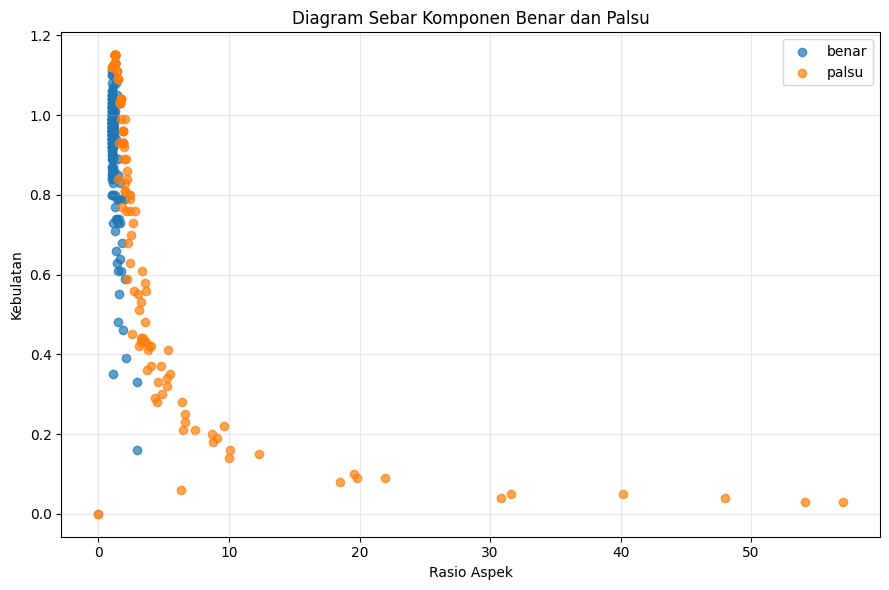

In [39]:

# Diagram sebar kebulatan terhadap rasio aspek

plt.figure(figsize=(9, 6))

for status in ["benar", "palsu"]:
    data = hasil_komponen[
        hasil_komponen["status"] == status
    ]

    plt.scatter(
        data["rasio_aspek"],
        data["kebulatan"],
        label=status,
        alpha=0.7
    )

plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.title("Diagram Sebar Komponen Benar dan Palsu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [40]:
# Menghitung luas mask bercak acuan
luas_acuan_px = np.count_nonzero(mb > 0)
luas_acuan_mm = luas_acuan_px * (MM_PER_PX ** 2)

print("Luas mask acuan:", luas_acuan_px, "piksel")
print("Luas mask acuan:", round(luas_acuan_mm, 2), "mm²")

Luas mask acuan: 3187 piksel
Luas mask acuan: 610.01 mm²


#**BAGIAN 5 INTEGRASI: Modul Analisis Bercak SIMUTEH**

#**Langkah 5.1 Kerjakan Sendiri: Melengkapi Modul**

**Kode 5.1 Kerangka src/bercak.py**

In [41]:

%%writefile /content/drive/MyDrive/SIMUTEH/simuteh-2330511078/src/bercak.py

"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""

import json
import cv2
import numpy as np

from utils_tepi import mask_daun_awal, bercak_awal


# Parameter bawaan
PARAM_BERCAK = {
    "kanal": 2,
    "k": 4.0,
    "se_bentuk": "elips",
    "se_open": 5,
    "se_close": 5,
    "luas_min": 20,
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,
    "batas_berat": 2.0,
    "mm_per_px": 0.4375,
}


# Bentuk structuring element
_BENTUK = {
    "elips": cv2.MORPH_ELLIPSE,
    "persegi": cv2.MORPH_RECT,
    "silang": cv2.MORPH_CROSS
}


def _se(p, uk):
    """Membuat structuring element sesuai parameter."""
    return cv2.getStructuringElement(
        _BENTUK[p["se_bentuk"]],
        (uk, uk)
    )


def bersihkan(biner, p):
    """Membersihkan mask bercak menggunakan opening dan closing."""

    # TODO 1: Opening
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(
            biner,
            cv2.MORPH_OPEN,
            _se(p, p["se_open"])
        )

    # TODO 2: Closing
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(
            biner,
            cv2.MORPH_CLOSE,
            _se(p, p["se_close"])
        )

    return biner


def ukur_dan_saring(biner, p):
    """Mengukur dan menyaring komponen bercak berdasarkan ukuran dan bentuk."""

    # TODO 3: Label komponen terhubung dengan konektivitas 8
    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (biner > 0).astype(np.uint8),
        connectivity=8
    )

    keluar = np.zeros_like(biner)
    daftar = []

    # TODO 4: Mengukur setiap komponen
    for i in range(1, n):

        # Mengambil kontur komponen
        kontur, _ = cv2.findContours(
            (lbl == i).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE
        )

        if len(kontur) == 0:
            continue

        cnt = kontur[0]

        # Luas komponen dalam piksel
        A = int(st[i, cv2.CC_STAT_AREA])

        # Keliling komponen
        keliling = cv2.arcLength(cnt, True)

        # Kebulatan
        kebulatan = (
            0.0 if keliling == 0
            else 4 * np.pi * A / keliling**2
        )

        # Rasio aspek
        w, h = cv2.minAreaRect(cnt)[1]
        rasio = max(w, h) / max(min(w, h), 1)

        # Luas dalam mm persegi
        luas_mm2 = A * p["mm_per_px"]**2

        # TODO 5: Penyaringan berdasarkan luas, kebulatan, dan rasio
        if (
            A >= p["luas_min"]
            and kebulatan >= p["bulat_min"]
            and rasio <= p["rasio_maks"]
        ):

            keluar[lbl == i] = 255

            daftar.append({
                "label": i,
                "luas_px": A,
                "luas_mm2": round(luas_mm2, 2),
                "keliling_px": round(keliling, 1),
                "kebulatan": round(kebulatan, 2),
                "rasio_aspek": round(rasio, 2),
                "cx": int(cen[i][0]),
                "cy": int(cen[i][1])
            })

    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""

    p = {**PARAM_BERCAK, **(p or {})}

    # Membuat mask daun
    m_daun = mask_daun_awal(img_praproses)

    # Membuat mask bercak awal
    biner = bercak_awal(
        img_praproses,
        m_daun,
        kanal=p["kanal"],
        k=p["k"]
    )

    # Membersihkan dan menyaring bercak
    m_bersih = bersihkan(biner, p)
    m_bercak, daftar = ukur_dan_saring(m_bersih, p)

    # TODO 6: Menghitung persentase bercak
    luas_daun = cv2.countNonZero(m_daun)
    luas_bercak = cv2.countNonZero(m_bercak)

    if luas_daun > 0:
        persen = luas_bercak / luas_daun * 100
    else:
        persen = 0.0

    # TODO 7: Menentukan kelas kondisi daun
    if persen >= p["batas_berat"]:
        kelas = "Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Ringan"
    else:
        kelas = "Sehat"

    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar
    }


def simpan_param(p, path="../hasil/param_bercak.json"):
    """Menyimpan parameter bercak ke file JSON."""

    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Overwriting /content/drive/MyDrive/SIMUTEH/simuteh-2330511078/src/bercak.py


In [42]:
import sys
import importlib

SRC = "/content/drive/MyDrive/SIMUTEH/simuteh-2330511078/src"

if SRC not in sys.path:
    sys.path.insert(0, SRC)

importlib.invalidate_caches()

import utils_tepi
import bercak

print("Import utils_tepi: BERHASIL")
print("Import bercak: BERHASIL")
print("Lokasi bercak:", bercak.__file__)

Import utils_tepi: BERHASIL
Import bercak: BERHASIL
Lokasi bercak: /content/drive/MyDrive/SIMUTEH/simuteh-2330511078/src/bercak.py


**Langkah 5.2 Evaluasi Menyeluruh**

**Kode 5.2 Evaluasi modul bercak.py**

In [43]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/SIMUTEH/simuteh-2330511078")

print("File label yang ditemukan:")

for f in PROJECT.rglob("label.csv"):
    print(f)

print("\nVariabel yang tersedia:")
for nama in ["label", "muat", "PARAM", "praproses", "jumlah_komponen"]:
    print(nama, "=", nama in globals())

File label yang ditemukan:
/content/drive/MyDrive/SIMUTEH/simuteh-2330511078/data/sintetis/label.csv

Variabel yang tersedia:
label = True
muat = True
PARAM = True
praproses = True
jumlah_komponen = True


In [44]:
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/SIMUTEH/simuteh-2330511078")
DATA = PROJECT / "data" / "sintetis"

label = pd.read_csv(DATA / "label.csv")

print("Jumlah data:", len(label))
print("Kolom:", label.columns.tolist())
print(label.head())

Jumlah data: 60
Kolom: ['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']
     nama_file  kelas  kondisi_cahaya  persen_bercak
0  teh_001.png  sehat          normal            0.0
1  teh_002.png  sehat           gelap            0.0
2  teh_003.png  sehat          terang            0.0
3  teh_004.png  sehat  kontras_rendah            0.0
4  teh_005.png  sehat        bayangan            0.0


In [45]:
import json
import inspect

# Periksa parameter bercak
with open(HASIL_DIR + "/param_bercak.json", "r") as f:
    print("PARAMETER BERCAK:")
    print(json.dumps(json.load(f), indent=4))

# Periksa fungsi praproses
print("\nFUNGSI PRAPROSES:")
print("Lokasi:", praproses.__module__)
print("Signature:", inspect.signature(praproses))
print(inspect.getsource(praproses))

PARAMETER BERCAK:
{
    "kanal": 2,
    "k": 4.0,
    "se_bentuk": "elips",
    "se_open": 5,
    "se_close": 5,
    "luas_min": 20,
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,
    "batas_berat": 2.0,
    "mm_per_px": 0.4375
}

FUNGSI PRAPROSES:
Lokasi: praproses
Signature: (img_bgr, p=None)
def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # TODO 1: Ubah ukuran citra, lebar sesuai parameter dan rasio aspek tetap
    tinggi_baru = int(img_bgr.shape[0] * p["lebar"] / img_bgr.shape[1])
    img = cv2.resize(
        img_bgr,
        (p["lebar"], tinggi_baru),
        interpolation=cv2.INTER_AREA
    )

    # TODO 2: Koreksi gamma
    if p["gamma"] != 1:
        gamma = p["gamma"]
        lut = np.array([
            255 * (i / 255) ** (1 / gamma)
            for i in range(256)
        ]).clip(0, 255).astype(np.uint8)

        img = cv2.LUT(img, lut)

    

In [46]:
from praproses import PARAM_BAWAAN

PARAM = PARAM_BAWAAN.copy()

print("Parameter praproses yang digunakan:")
print(PARAM)

Parameter praproses yang digunakan:
{'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


In [47]:
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/SIMUTEH/simuteh-2330511078/data/sintetis")

for folder in DATA_DIR.iterdir():
    print(f"\nFolder: {folder.name}")

    if folder.is_dir():
        print("Contoh file:", [p.name for p in list(folder.iterdir())[:5]])


Folder: label.csv

Folder: mask_daun
Contoh file: ['teh_037.png', 'teh_051.png', 'teh_025.png', 'teh_026.png', 'teh_032.png']

Folder: mask_bercak
Contoh file: ['teh_037.png', 'teh_051.png', 'teh_025.png', 'teh_026.png', 'teh_032.png']

Folder: bersih
Contoh file: ['teh_037.png', 'teh_051.png', 'teh_025.png', 'teh_026.png', 'teh_032.png']

Folder: citra
Contoh file: ['teh_037.png', 'teh_051.png', 'teh_025.png', 'teh_026.png', 'teh_032.png']


In [48]:
import importlib
import bercak
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Muat ulang modul bercak
importlib.reload(bercak)

# Gunakan parameter bercak yang sudah disimpan
with open(HASIL_DIR + "/param_bercak.json", "r") as f:
    PB = json.load(f)

# Pastikan folder hasil tersedia
Path(HASIL_DIR).mkdir(parents=True, exist_ok=True)

print("Parameter bercak:", PB)
print("Jumlah data evaluasi:", len(label))

Parameter bercak: {'kanal': 2, 'k': 4.0, 'se_bentuk': 'elips', 'se_open': 5, 'se_close': 5, 'luas_min': 20, 'bulat_min': 0.5, 'rasio_maks': 1.8, 'batas_ringan': 0.1, 'batas_berat': 2.0, 'mm_per_px': 0.4375}
Jumlah data evaluasi: 60


Galat absolut rerata persen bercak: 0.582
Korelasi persen prediksi vs acuan: 0.954
Akurasi kelas: 0.883
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             16              4      0
Bercak Ringan             0             19      1
Sehat                     0              2     18
kondisi
bayangan          0.92
gelap             1.00
kontras_rendah    0.75
normal            0.75
terang            1.00
Name: benar, dtype: float64


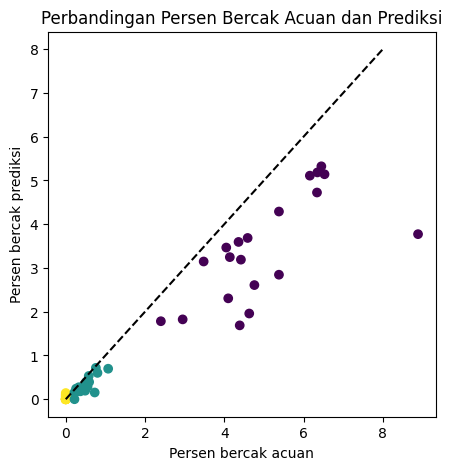


Jumlah data evaluasi: 60
CSV tersimpan: True
Parameter tersimpan: True


In [49]:

import importlib
import bercak
importlib.reload(bercak)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Parameter kosong = menggunakan parameter bawaan
PB = {}

# Simpan parameter yang digunakan
bercak.simpan_param(
    PB,
    path=str(HASIL / "param_bercak.json")
)

baris = []

# Evaluasi seluruh 60 citra
for _, d in label.iterrows():

    img, md, mb = muat(d.nama_file)

    h = bercak.analisis_daun(
        praproses(img, PARAM),
        PB
    )

    baris.append([
        d.nama_file,
        d.kelas,
        d.kondisi_cahaya,
        d.persen_bercak,
        h["persen_bercak"],
        jumlah_komponen(mb),
        h["jumlah_bercak"],
        h["kelas"]
    ])

# Membuat DataFrame evaluasi
ev = pd.DataFrame(
    baris,
    columns=[
        "nama",
        "kelas",
        "kondisi",
        "persen_acuan",
        "persen_prediksi",
        "jumlah_acuan",
        "jumlah_prediksi",
        "kelas_prediksi"
    ]
)

# Menyesuaikan nama kelas acuan
ev["kelas_acuan"] = ev.kelas.map({
    "sehat": "Sehat",
    "ringan": "Bercak Ringan",
    "berat": "Bercak Berat"
})

# Menyesuaikan nama kelas prediksi
ev["kelas_prediksi"] = ev.kelas_prediksi.map({
    "Sehat": "Sehat",
    "Ringan": "Bercak Ringan",
    "Berat": "Bercak Berat"
})

# Menyimpan hasil evaluasi
ev.to_csv(
    HASIL / "p6_evaluasi_bercak.csv",
    index=False
)

# Menghitung galat absolut rerata
print(
    "Galat absolut rerata persen bercak:",
    (ev.persen_prediksi - ev.persen_acuan)
    .abs().mean().round(3)
)

# Menghitung korelasi
print(
    "Korelasi persen prediksi vs acuan:",
    ev[["persen_prediksi", "persen_acuan"]]
    .corr().iloc[0, 1].round(3)
)

# Menghitung akurasi kelas
print(
    "Akurasi kelas:",
    (ev.kelas_prediksi == ev.kelas_acuan)
    .mean().round(3)
)

# Matriks kebingungan
print(
    pd.crosstab(
        ev.kelas_acuan,
        ev.kelas_prediksi,
        rownames=["acuan"],
        colnames=["prediksi"]
    )
)

# Akurasi berdasarkan kondisi cahaya
print(
    ev.assign(
        benar=ev.kelas_prediksi == ev.kelas_acuan
    )
    .groupby("kondisi").benar.mean().round(2)
)

# Grafik hubungan persen bercak acuan dan prediksi
plt.figure(figsize=(5, 5))

plt.scatter(
    ev.persen_acuan,
    ev.persen_prediksi,
    c=ev.kelas.astype("category").cat.codes
)

plt.plot([0, 8], [0, 8], "k--")

plt.xlabel("Persen bercak acuan")
plt.ylabel("Persen bercak prediksi")
plt.title("Perbandingan Persen Bercak Acuan dan Prediksi")

plt.show()

print("\nJumlah data evaluasi:", len(ev))
print("CSV tersimpan:", (HASIL / "p6_evaluasi_bercak.csv").is_file())
print("Parameter tersimpan:", (HASIL / "param_bercak.json").is_file())

#**Langkah 5.3 Kerjakan Sendiri**

**Kode 5.3:  Analisis Kesalahan**


In [50]:
#Kode 5.3 Kerjakan sendiri

import matplotlib.pyplot as plt
import cv2

# Mengambil citra yang salah diklasifikasikan
salah = ev[ev["kelas_acuan"] != ev["kelas_prediksi"]].copy()

print("Jumlah citra salah:", len(salah))
print("\nDaftar citra yang salah:")
print(
    salah[["nama", "kelas_acuan", "kelas_prediksi", "kondisi"]]
    .to_string(index=False)
)

# Menampilkan setiap citra yang salah
for _, d in salah.iterrows():

    img, md, mb = muat(d["nama"])

    # Citra hasil praproses
    img_proses = praproses(img, PARAM)

    # Hasil deteksi bercak
    hasil = bercak.analisis_daun(img_proses, PB)
    mask_prediksi = hasil["mask_bercak"]

    # Menampilkan tiga citra berdampingan
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    ax[0].imshow(cv2.cvtColor(img_proses, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Citra Hasil Praproses")

    ax[1].imshow(mask_prediksi, cmap="gray")
    ax[1].set_title("Mask Bercak Hasil")

    ax[2].imshow(mb, cmap="gray")
    ax[2].set_title("Mask Bercak Acuan")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f'{d["nama"]} | Acuan: {d["kelas_acuan"]} | '
        f'Prediksi: {d["kelas_prediksi"]} | '
        f'Kondisi: {d["kondisi"]}'
    )

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [51]:
import inspect
print(inspect.signature(bercak.analisis_daun))
print(inspect.getdoc(bercak.analisis_daun))

(img_praproses, p=None)
Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis.


In [56]:
import pandas as pd
from pathlib import Path

HASIL_DIR = Path("/content/drive/MyDrive/SIMUTEH/simuteh-2330511078/hasil")

print("=== EVALUASI BERCAK P6 ===")
df_p6 = pd.read_csv(HASIL_DIR / "p6_evaluasi_bercak.csv")
display(df_p6)

print("=== EKSPERIMEN STRUCTURING ELEMENT P6 ===")
df_se = pd.read_csv(HASIL_DIR / "p6_eksperimen_se.csv")
display(df_se)

=== EVALUASI BERCAK P6 ===


,nama,kelas,kondisi,persen_acuan,persen_prediksi,jumlah_acuan,jumlah_prediksi,kelas_prediksi,kelas_acuan
0,teh_001.png,sehat,normal,0.00,0.041,0,1,Sehat,Sehat
1,teh_002.png,sehat,gelap,0.00,0.000,0,0,Sehat,Sehat
2,teh_003.png,sehat,terang,0.00,0.000,0,0,Sehat,Sehat
3,teh_004.png,sehat,kontras_rendah,0.00,0.000,0,0,Sehat,Sehat
4,teh_005.png,sehat,bayangan,0.00,0.044,0,1,Sehat,Sehat
5,teh_006.png,sehat,normal,0.00,0.141,0,3,Bercak Ringan,Sehat
6,teh_007.png,sehat,gelap,0.00,0.000,0,0,Sehat,Sehat
7,teh_008.png,sehat,terang,0.00,0.000,0,0,Sehat,Sehat
8,teh_009.png,sehat,kontras_rendah,0.00,0.000,0,0,Sehat,Sehat
9,teh_010.png,sehat,bayangan,0.00,0.000,0,0,Sehat,Sehat


=== EKSPERIMEN STRUCTURING ELEMENT P6 ===


,kelas,k,bentuk,ukuran,galat_jumlah,IoU
0,sehat,3,persegi,3,4,NaN
1,sehat,3,persegi,5,3,NaN
2,sehat,3,persegi,7,0,NaN
3,sehat,3,elips,3,8,NaN
4,sehat,3,elips,5,3,NaN
...,...,...,...,...,...,...
1615,berat,6,elips,5,0,0.718847
1616,berat,6,elips,7,0,0.718585
1617,berat,6,silang,3,0,0.720570
1618,berat,6,silang,5,0,0.716806
